# STATE OPUS-R2 — Chemical structure and mechanism coverage

All analysis code is inline. Use Python 3.11 with numpy 1.26.4, pandas 2.2.2, scipy 1.13.1, statsmodels 0.14.2, matplotlib 3.9.4, RDKit 2026.3.3, IPython and ipykernel. Model evaluation uses released scores; no inference is required. `STATE_PUBLIC_INPUTS` and `STATE_RELEASE_INPUTS` can select verified raw caches.

## 1. Data source and acquisition

Download the pinned official STATE per-condition score files. The checksum-pinned companion bundle supplies condition identities, drug annotations and dated ontology membership snapshots.

In [1]:
from pathlib import Path
import os,json,hashlib,time,platform,urllib.request,urllib.parse,zipfile,shutil,ast,itertools
os.environ['OMP_NUM_THREADS']='1';os.environ['OPENBLAS_NUM_THREADS']='1'
import numpy as np
import pandas as pd
from scipy.stats import spearmanr,pearsonr,rankdata,mannwhitneyu
import statsmodels.api as sm
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display
START=time.time()
CACHE=Path(os.environ.get('STATE_PUBLIC_INPUTS','state_public_inputs')).resolve();CACHE.mkdir(parents=True,exist_ok=True)
RELEASES=Path(os.environ.get('STATE_RELEASE_INPUTS','state_releases')).resolve();RELEASES.mkdir(parents=True,exist_ok=True)
WORK=Path('test-02_outputs').resolve();(WORK/'data').mkdir(parents=True,exist_ok=True);(WORK/'spectra_run/artifacts').mkdir(parents=True,exist_ok=True)
def sha(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(8388608),b''):h.update(b)
    return h.hexdigest()
def fetch(url,p,size,digest):
    if p.exists() and p.stat().st_size==size and sha(p)==digest:return p
    p.parent.mkdir(parents=True,exist_ok=True);tmp=p.with_suffix(p.suffix+'.part')
    with urllib.request.urlopen(urllib.request.Request(url,headers={'User-Agent':'STATE-notebook/1.0'}),timeout=180) as source,tmp.open('wb') as target:
        shutil.copyfileobj(source,target,8388608)
    if tmp.stat().st_size!=size or sha(tmp)!=digest:raise ValueError('Source identity mismatch: '+str(p))
    tmp.replace(p);return p
archive=fetch('https://github.com/shreyjain11/SPECTRAagent/releases/download/notebook-inputs-2026-11-08-v1/state-inputs.zip',CACHE/'state-inputs.zip',440390168,'fb45e9305dcf32bfa9d68ff910f7539707b3e4ff58c695db2e8c5ee8a9e8a9fc')
P=CACHE/'public_bundle/assets/state-opus-r2'
with zipfile.ZipFile(archive) as z:
    inventory=json.loads(z.read('STATE_INPUTS.json'))
    required=[k for k in inventory if k.startswith('state-opus-r2/') and (k.endswith('data/predictions.csv') or ('spectra_run/artifacts/' in k and k.endswith('.json')))]
    for k in required:
        target=CACHE/'public_bundle/assets'/k;x=inventory[k]
        if target.exists() and target.stat().st_size==x['bytes'] and sha(target)==x['sha256']:continue
        target.parent.mkdir(parents=True,exist_ok=True)
        with z.open('assets/'+k) as source,target.open('wb') as dest:shutil.copyfileobj(source,dest)
        if sha(target)!=x['sha256']:raise ValueError(k)
print('Verified input annotation files:',len(required))

from io import BytesIO
from IPython.display import Image
def display_figure(figure):
    buffer=BytesIO()
    figure.savefig(buffer,format='png',dpi=140,bbox_inches='tight')
    display(Image(data=buffer.getvalue()))


Verified input annotation files: 8


In [2]:
SOURCES = [{'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv',
  'bytes': 276570,
  'sha256': 'ca5377b00f6700bee2b4b17eeaf4e703fc2d3797ac8271c2f282088fcbb289e8',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'bytes': 269473,
  'sha256': '489cbe64636b7765fe7f24fe5536da9fb1ee86226effd9eeb422634d5731396b',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 284828,
  'sha256': '49e3ce723ec7ca6bfc044d438902129ffb9ec2682d33a73e16693735c4746ad4',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/Hs 766T_results.csv',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/Hs 766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/Hs '
         '766T_results.csv',
  'bytes': 275993,
  'sha256': 'f391f46e60061332b2a555567443aeb3190239c4bdac146bcb3340d503aeebe9',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 272057,
  'sha256': '2654fe5b526d577807a63b30a9c85a70d829979afe452325650071a3f22a03ae',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_results.csv',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_results.csv',
  'bytes': 468117,
  'sha256': 'a0de78f621e8c6dfc67ac6ab6acbbab65fbd3aaddf7e56732ed6f03569d39f94',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'bytes': 459434,
  'sha256': 'e3fef3287ccc5f38ac64c1c249915684a11dda7b38b43884b1f636cde792364a',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 479496,
  'sha256': '8f953408f94eadc1461851599a33e2a4f84e413621d5ee54a52a8746c2037691',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs 766T_results.csv',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs '
          '766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs '
         '766T_results.csv',
  'bytes': 466949,
  'sha256': 'b9ab34b3d93a414e5db0650aaad70fb9bc558abade0e4c4eb3322ab3e4a47080',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 461203,
  'sha256': '2171a50b43d55ed6a5fae82c50685fd519b21b3a821872cb0e147a338d26a332',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/C32_results.csv',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/C32_results.csv',
  'bytes': 281263,
  'sha256': '9fee724f7d5dc46a3e0061e264347ce4c8c5c29b6c0dac2dc67303bcae25894a',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/HOP62_results.csv',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/HOP62_results.csv',
  'bytes': 269030,
  'sha256': '646052bbdb9844e1a2b94f19c095d0f5a07db9529010f41252c61ba228544d56',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 287583,
  'sha256': '9106d01893815fbf77d85f4e2351da8a607adedc74edb62cc452c110812b09a2',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/Hs 766T_results.csv',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/Hs 766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/Hs '
         '766T_results.csv',
  'bytes': 277100,
  'sha256': '80c38255fdce0444457f909d7ef9c2186a82c5476550bfe82604bd48896aae72',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/PANC-1_results.csv',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 273025,
  'sha256': '5a40d67c26a428487d3b0f602b5b7a69006b5c4595eaaf0ffb5f44eaf5160239',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/C32_results.csv',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/C32_results.csv',
  'bytes': 468674,
  'sha256': 'cfb3517443ea659341b6be94f8b6828ef912ce21e0f3a0be4f3c5b29cd2dbc79',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HOP62_results.csv',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HOP62_results.csv',
  'bytes': 463111,
  'sha256': 'dedd141ec8fdff513a19cb46f3bb95b76372b117935620b02f50f2f8e339d33d',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 473841,
  'sha256': 'a3c6d89ea4f07e395aac68db6a36222ced41f6acea648e8e5d008cd5912cf0fb',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/Hs 766T_results.csv',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/Hs '
          '766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/Hs '
         '766T_results.csv',
  'bytes': 468068,
  'sha256': '4904a9d8a3ed52a2cccd9de85cd0eeec0277bcc07d184eefb8096395719a2746',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/PANC-1_results.csv',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 464280,
  'sha256': '8483133246cf1dba89c76a94f8a407757f4714bff5c9534f66890fbfe3d7ec03',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'path': 'scores/ST-HVG-Replogle/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 360951,
  'sha256': '42dd8ef412843c9e0782c72d669ef352d40af63fbe7f1d11ab26b9d0f188a5e3',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'path': 'scores/ST-HVG-Replogle/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 423657,
  'sha256': 'fff2d8598e61229052483d2215809b267a9be5b28187147ea8eaa078a115280d',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/k562/eval_best.ckpt/k562_results.csv',
  'path': 'scores/ST-HVG-Replogle/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 368088,
  'sha256': 'c518efe5a6492b62dd3aea985e6f50ca5a8b2e9df742134041e313d2e6605ba6',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'path': 'scores/ST-HVG-Replogle/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 406063,
  'sha256': '397533d40a2efba9d75a54fca855fc39db1562ff50c765408e9afdea61826803',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'path': 'scores/ST-HVG-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 506756,
  'sha256': '0c930ad038b56c6f43d25896a15cd68e121d8902e5457718b4dfc9f163f10604',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'path': 'scores/ST-HVG-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 582103,
  'sha256': '3efc817549bbf24edd6e427fb99466f58de8fadb3a4b4335523f5cfac1bc8098',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'path': 'scores/ST-HVG-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 538095,
  'sha256': '8bd145c4667e03c9e367079dcfb38126e4e1f06b562f8a3fa6d1eaa1d0ba5821',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'path': 'scores/ST-HVG-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 575323,
  'sha256': 'c187b3a026c8381a84acbe5035efa30947a6774c82a6519749b1b37e85fdd14d',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'path': 'scores/ST-SE-Replogle/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 354986,
  'sha256': '1e4cd7df90212c61f7f171fcd5da69449e5e3edde4462201b8dedd99d07aa2c4',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'path': 'scores/ST-SE-Replogle/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 403167,
  'sha256': '7352c785869bf83402fb5dc79ebdbb2d911d77153c3530db4b9f143a5bec2626',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/k562/eval_best.ckpt/k562_results.csv',
  'path': 'scores/ST-SE-Replogle/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 365675,
  'sha256': 'bcba9ae671c391e78b11efda0bb0d3d48f8052541ae7599d522b293e96e3594c',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'path': 'scores/ST-SE-Replogle/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 411935,
  'sha256': '36b6afce7889485a2afa99a13449b59dbd06d14d564e985a37629f93101ffd34',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'path': 'scores/ST-SE-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 509894,
  'sha256': '9b7b329faa11cfdfbbac37ad571bdf47e8af7f988d61561eab51d80dce9d643a',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'path': 'scores/ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 568100,
  'sha256': '372db67f297565e5542cac1bda688586c07e03e92a999bea953a9df812ba5317',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'path': 'scores/ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 528013,
  'sha256': 'eaf22cc6169fa98ab90913366529db232ac2109fe421599f66d47b14ffd183b3',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'path': 'scores/ST-SE-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 535692,
  'sha256': 'ce7034b9e7af7255f44347ac9fdcbdd41e13b8ce674cab3c2700c0b41a1b1ffa',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'path': 'scores/ST-HVG-Parse/fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'bytes': 23267,
  'sha256': '09553a37706d948fddf8cf5bacf5b88880cf3cfb90a2b866f08524b49e909401',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'path': 'scores/ST-HVG-Parse/fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'bytes': 22921,
  'sha256': 'e9d288b06289e24e7928b9a79ccce8ed74a702c9b2fdf92c5a6470aeb11cdbc1',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'path': 'scores/ST-HVG-Parse/fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'bytes': 20723,
  'sha256': '202ca8338564bcdc2a7c68007b0976800b4dbb7ca5e6d8a0799b0d428615233c',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'path': 'scores/ST-HVG-Parse/fewshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'bytes': 21260,
  'sha256': '13935da60494fb572039e10aed4f44748bf9e7e8dd0ee2acf4fe8bcfe158a852',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'path': 'scores/ST-HVG-Parse/fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'bytes': 21542,
  'sha256': '1030abc5a7bd1cb1b9c692c35ba4ce16d0515d299dec9c7cf50eb2ede9641a65',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'bytes': 33745,
  'sha256': 'f6a553831669d4f5fb0a6957d7f32e815a4fa5be89a0cf13677396b6039aa157',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'bytes': 32762,
  'sha256': '9a7f4a4c564d25dc2cfe06e25367ae936dc50873aa5711ad26e5d1e3f46d0916',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'bytes': 27434,
  'sha256': '50b1d9d6f15cbd9d27ccb17e07605f21b94a0e461d346555d81b7d911694d5ec',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'bytes': 31420,
  'sha256': '84f0f00cd17c871b879ee38d92ce5183241c38e1afb20405f3b00e361c98eaa1',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'bytes': 31512,
  'sha256': 'df68464d3caf07c7c5129a0d911d10ba17c75020e7ac866e4afde28155ac4786',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'path': 'scores/ST-SE-Parse/fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'bytes': 23028,
  'sha256': '06ef8b31481e21845e29eb3408827469eb7da67c01e17c315d2e82d77ddd325a',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'path': 'scores/ST-SE-Parse/fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'bytes': 22494,
  'sha256': '0073fb52db8657ccb14815b58025f53f89abde3a27eb1614c650e930375d3f60',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'path': 'scores/ST-SE-Parse/fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'bytes': 20130,
  'sha256': '87c04e97d215f7bda9a13d602472e62db0be919dc791ab4c4d4732f5a48cf06c',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'path': 'scores/ST-SE-Parse/fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'bytes': 21275,
  'sha256': '3d8466310099d70f91a69725fb0e181e1fd541f57ed644daab5c41be6ae1b88d',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'path': 'scores/ST-SE-Parse/zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'bytes': 33911,
  'sha256': '41377aad49e688a710264d343378e5bc6ce1a698880b8bb1c4f0be9ad025c48f',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'path': 'scores/ST-SE-Parse/zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'bytes': 33789,
  'sha256': 'bb35f1b85f8d9603b10fcf8706602b122bdc520548c9c53f891386dcd40026a1',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'path': 'scores/ST-SE-Parse/zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'bytes': 28814,
  'sha256': '73b37fc58ca8a8734dc5cc34c6b44ec94cdbb6ccb47dadfb3c5bccedf8c99655',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'path': 'scores/ST-SE-Parse/zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'bytes': 31883,
  'sha256': '2cbac97ecdeee9ae7333245fc4d06860969d17d38f2fc4ebea8f99e8af5657fa',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'path': 'scores/ST-SE-Parse/zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'bytes': 30873,
  'sha256': '579286dcc83ffaead762b234891442b560b6213d847956d87147389323c7df5b',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'}]

## 2. Data processing

Join released results to exact repository/path/perturbation identities. Keep the protocol, representation, context and annotation fields explicit. Each condition is retained once.

In [3]:
# Read only source identities and annotations from the bundle; model-score columns
# are loaded separately from the pinned official CSVs below.
annotation_columns=['source_repo','source_path','dataset_family','protocol','context','split_id','representation','perturbation','perturbation_name','dose','dose_unit','perturbation_norm','perturbation_loose','row_key','drug_metadata_match']
annotation_columns += [c for c in pd.read_csv(P/'data/predictions.csv',nrows=0).columns if c.startswith('drugmeta_')]
annotations=pd.read_csv(P/'data/predictions.csv',usecols=annotation_columns,low_memory=False)
assert not annotations.duplicated(['source_repo','source_path','perturbation']).any()
score_parts=[]
for x in SOURCES:
    p=fetch(x['url'],RELEASES/x['path'],x['bytes'],x['sha256'])
    s=pd.read_csv(p);s['source_repo']=x['repo'];s['source_path']=x['filename'];score_parts.append(s)
released=pd.concat(score_parts,ignore_index=True)
raw=annotations.merge(released,on=['source_repo','source_path','perturbation'],how='left',validate='one_to_one')
assert len(raw)==len(annotations) and raw.overlap_at_N.notna().all()
raw.to_csv(WORK/'data/predictions.csv',index=False)
for p in (P/'spectra_run/artifacts').glob('*.json'):
    shutil.copy2(p,WORK/'spectra_run/artifacts'/p.name)
genes=set(raw.loc[raw.dataset_family=='Replogle-Nadig','perturbation'].str.upper())
tahoe=raw[raw.dataset_family=='Tahoe-100M'].copy()
display(raw.groupby(['dataset_family','protocol','representation']).size().rename('condition_rows'))


dataset_family  protocol  representation
Parse-PBMC      fewshot   HVG                310
                          SE                 248
                zeroshot  HVG                450
                          SE                 450
Replogle-Nadig  fewshot   HVG               4058
                          SE                4058
                zeroshot  HVG               5759
                          SE                5759
Tahoe-100M      fewshot   HVG               3674
                          SE                3674
                zeroshot  HVG               5684
                          SE                5684
Name: condition_rows, dtype: int64

## 3. Axis definition and level construction

Chemical coverage uses leave-one-out nearest-neighbor Morgan Tanimoto similarity. Mechanism-of-action and target annotations provide a separate categorical diagnostic.

In [6]:
import pandas as pd, numpy as np
from rdkit import Chem
from rdkit.Chem import AllChem, DataStructs
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')
df = pd.read_csv(WORK / 'data/predictions.csv', low_memory=False)
t = df[df.dataset_family == 'Tahoe-100M'].copy()
du = t.drop_duplicates('perturbation_name')[['perturbation_name', 'drugmeta_canonical_smiles', 'drugmeta_moa-fine', 'drugmeta_targets', 'drugmeta_human-approved']].reset_index(drop=True)
fps = {}
for _, r in du.iterrows():
    s = r['drugmeta_canonical_smiles']
    if pd.isna(s):
        continue
    m = Chem.MolFromSmiles(str(s))
    if m is None:
        continue
    fps[r['perturbation_name']] = AllChem.GetMorganFingerprintAsBitVect(m, 2, nBits=2048)
print('fingerprints computed for', len(fps), '/', len(du), 'drugs')
names = list(fps.keys())
nn_sim = {}
mean_top5 = {}
for i, n in enumerate(names):
    sims = DataStructs.BulkTanimotoSimilarity(fps[n], [fps[m] for m in names])
    sims = np.array(sims)
    sims[i] = -1
    order = np.sort(sims)[::-1]
    nn_sim[n] = order[0]
    mean_top5[n] = order[:5].mean()
nn = pd.Series(nn_sim)
print('\nnearest-neighbor Tanimoto distribution across drugs:')
print(nn.describe().round(3))
print('quartiles:', np.percentile(list(nn_sim.values()), [0, 25, 50, 75, 100]).round(3))
feat = du.copy()
feat['nn_tanimoto'] = feat['perturbation_name'].map(nn_sim)
feat['meantop5_tanimoto'] = feat['perturbation_name'].map(mean_top5)
feat['chem_novelty'] = 1 - feat['nn_tanimoto']
feat.to_csv(WORK / 'spectra_run/artifacts/tahoe_drug_features.csv', index=False)
print('\nsaved tahoe_drug_features.csv')
z = t[t.protocol == 'zeroshot'].merge(feat[['perturbation_name', 'chem_novelty', 'nn_tanimoto']], on='perturbation_name', how='left')
z = z.dropna(subset=['chem_novelty'])
from scipy.stats import spearmanr
for rep in ['HVG', 'SE']:
    zz = z[z.representation == rep]
    rho, p = spearmanr(zz['nn_tanimoto'], zz['overlap_at_N'])
    print(f'PILOT zeroshot {rep}: spearman(nn_tanimoto, overlap)={rho:.3f} p={p:.1e} n={len(zz)}  (expect POSITIVE: more similar->better)')

fingerprints computed for 377 / 379 drugs

nearest-neighbor Tanimoto distribution across drugs:
count    377.000
mean       0.428
std        0.259
min        0.061
25%        0.241
50%        0.300
75%        0.565
max        1.000
dtype: float64
quartiles: [0.061 0.241 0.3   0.565 1.   ]

saved tahoe_drug_features.csv
PILOT zeroshot HVG: spearman(nn_tanimoto, overlap)=0.023 p=8.0e-02 n=5654  (expect POSITIVE: more similar->better)
PILOT zeroshot SE: spearman(nn_tanimoto, overlap)=0.056 p=2.5e-05 n=5654  (expect POSITIVE: more similar->better)


## 4. Model results and released scores

The primary metric is released `overlap_at_N`; higher is better. Fixed-N overlaps, DE counts, representation changes and protocol changes remain separate controls. Drug-level analyses average all eligible condition rows within drug.

In [4]:
display(raw.groupby(['dataset_family','protocol','representation']).agg(n=('overlap_at_N','size'),mean_overlap=('overlap_at_N','mean')))

n  mean_overlap
dataset_family protocol representation                    
Parse-PBMC     fewshot  HVG              310      0.340005
                        SE               248      0.361973
               zeroshot HVG              450      0.243795
                        SE               450      0.312989
Replogle-Nadig fewshot  HVG             4058      0.229432
                        SE              4058      0.177416
               zeroshot HVG             5759      0.137164
                        SE              5759      0.073739
Tahoe-100M     fewshot  HVG             3674      0.525368
                        SE              3674      0.515642
               zeroshot HVG             5684      0.241807
                        SE              5684      0.142238

## 5. Curves and controls

In [5]:
def draw(data,x,y,group):
    rng=np.random.default_rng(7);rows=[]
    for keys,g in data.groupby([group,x],observed=True,sort=True):
        values=g[y].dropna().to_numpy();boot=np.array([rng.choice(values,len(values),replace=True).mean() for _ in range(2000)])
        rows.append({group:keys[0],x:keys[1],'n':len(values),'mean':values.mean(),'lo':np.quantile(boot,.025),'hi':np.quantile(boot,.975)})
    tab=pd.DataFrame(rows);display(tab)
    fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
    for label,g in tab.groupby(group,sort=False):
        ix=np.arange(len(g));ax.errorbar(ix,g['mean'],yerr=np.maximum(0,np.vstack([g['mean']-g.lo,g.hi-g['mean']])),marker='o',capsize=3,label=str(label));ax.set_xticks(ix,g[x].astype(str),rotation=20)
    ax.set(xlabel=x,ylabel=y);ax.legend();ax.grid(alpha=.2);display_figure(fig);plt.close(fig)
    return tab

def partial_spearman(frame,x,y,controls):
    d=frame[[x,y,*controls]].dropna();a=rankdata(d[x]);b=rankdata(d[y]);C=np.column_stack([np.ones(len(d)),*[rankdata(d[c]) for c in controls]])
    a=a-C@np.linalg.lstsq(C,a,rcond=None)[0];b=b-C@np.linalg.lstsq(C,b,rcond=None)[0]
    return pearsonr(a,b)


,representation,level,n,mean,lo,hi
0,HVG,"(0.0602, 0.241]",1425,0.239905,0.232469,0.247175
1,HVG,"(0.241, 0.3]",1409,0.236043,0.228653,0.243123
2,HVG,"(0.3, 0.565]",1410,0.242908,0.235675,0.250345
3,HVG,"(0.565, 1.0]",1410,0.246254,0.238886,0.253672
4,SE,"(0.0602, 0.241]",1425,0.136985,0.130620,0.143336
5,SE,"(0.241, 0.3]",1409,0.134482,0.128265,0.140864
6,SE,"(0.3, 0.565]",1410,0.143198,0.136432,0.150311
7,SE,"(0.565, 1.0]",1410,0.152069,0.144810,0.159652


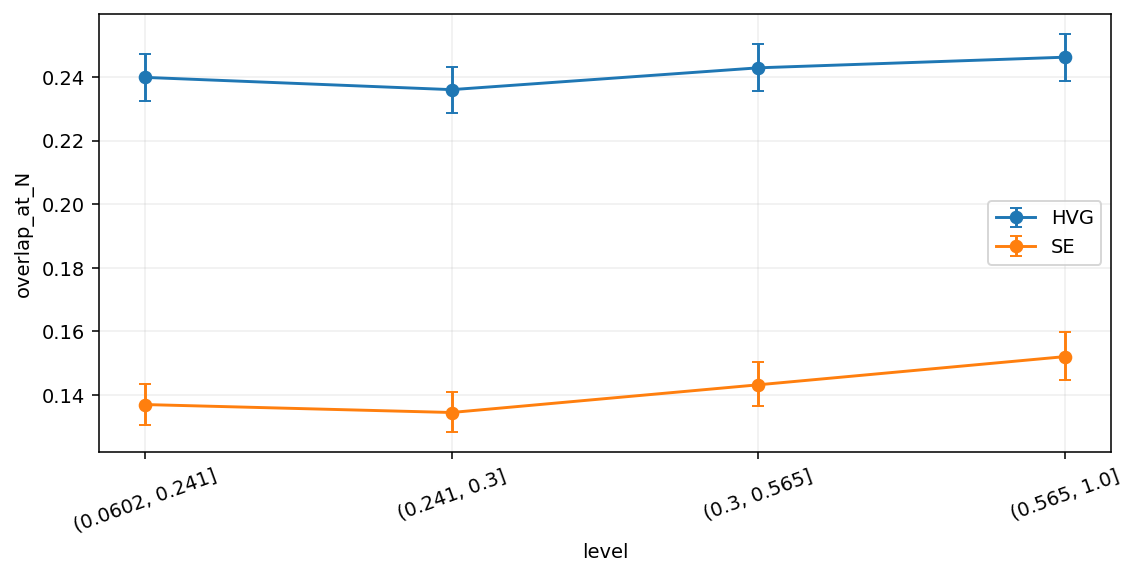

n  mean_overlap
representation drugmeta_moa-fine                                  
HVG            Adrenoceptor agonist              190      0.326501
               Androgen receptor antagonist       95      0.359087
               CDK inhibitor                     150      0.404410
               Cyclooxygenase inhibitor          340      0.359364
               DNA methyltransferase inhibitor    85      0.316689
               DNA synthesis/repair inhibitor    645      0.375243
               EGFR/ERBB inhibitor               285      0.320448
               GSK3 inhibitor                     90      0.355851
               Glucocorticoid receptor agonist   140      0.402154
               Glucose transporter inhibitor     110      0.391115
               HDAC inhibitor                     85      0.416834
               JAK/STAT inhibitor                170      0.360846
               MEK inhibitor                     120      0.358926
               MTOR inhibitor                    210      0.394353
               Microtubule inhibitor             195      0.430538
               Multi-TK inhibitor                230      0.347921
               Other MAPK inhibitor              255      0.343451
               Other TK inhibitor                330      0.332206
               PI3K/AKT inhibitor                135      0.360929
               Proteasome inhibitor               85      0.444211
               Protein synthesis inhibitor       165      0.400128
               RAF inhibitor                      88      0.388917
               RAS inhibitor                     105      0.354337
               Retinoic receptor agonist         110      0.395971
               Sonic inhibitor                    70      0.324460
               unclear                          4875      0.340505
SE             Adrenoceptor agonist              190      0.276915
               Androgen receptor antagonist       95      0.294481
               CDK inhibitor                     150      0.324654
               Cyclooxygenase inhibitor          340      0.293063
               DNA methyltransferase inhibitor    85      0.235633
               DNA synthesis/repair inhibitor    645      0.304596
               EGFR/ERBB inhibitor               285      0.249447
               GSK3 inhibitor                     90      0.248793
               Glucocorticoid receptor agonist   140      0.334154
               Glucose transporter inhibitor     110      0.330721
               HDAC inhibitor                     85      0.367877
               JAK/STAT inhibitor                170      0.317010
               MEK inhibitor                     120      0.263751
               MTOR inhibitor                    210      0.331085
               Microtubule inhibitor             195      0.358109
               Multi-TK inhibitor                230      0.261239
               Other MAPK inhibitor              255      0.257977
               Other TK inhibitor                330      0.262243
               PI3K/AKT inhibitor                135      0.258661
               Proteasome inhibitor               85      0.358301
               Protein synthesis inhibitor       165      0.337336
               RAF inhibitor                      88      0.336967
               RAS inhibitor                     105      0.295791
               Retinoic receptor agonist         110      0.361267
               Sonic inhibitor                    70      0.276307
               unclear                          4875      0.281329

In [7]:
data=z.copy();data['level']=pd.qcut(data.nn_tanimoto,4,duplicates='drop');curve=draw(data,'level','overlap_at_N','representation')
moa=t.groupby(['representation','drugmeta_moa-fine'],dropna=True).agg(n=('overlap_at_N','size'),mean_overlap=('overlap_at_N','mean'));display(moa[moa.n>=20])

## 6. What the agent decided, and why

Chemical structural coverage is not retained when the association is weak or inconsistent; the panel is a coverage proxy and does not establish unseen training chemistry.

In [8]:
if 'curve' in globals():
    display(curve)
    for group,q in curve.groupby(curve.columns[0],observed=True):
        if 'mean' in q:print('Ordered mean-score steps:',group,np.diff(q['mean'].to_numpy()))
print('Read the calculated controls above together with the axis curve; a raw association alone does not establish model-specific generalization.')

,representation,level,n,mean,lo,hi
0,HVG,"(0.0602, 0.241]",1425,0.239905,0.232469,0.247175
1,HVG,"(0.241, 0.3]",1409,0.236043,0.228653,0.243123
2,HVG,"(0.3, 0.565]",1410,0.242908,0.235675,0.250345
3,HVG,"(0.565, 1.0]",1410,0.246254,0.238886,0.253672
4,SE,"(0.0602, 0.241]",1425,0.136985,0.130620,0.143336
5,SE,"(0.241, 0.3]",1409,0.134482,0.128265,0.140864
6,SE,"(0.3, 0.565]",1410,0.143198,0.136432,0.150311
7,SE,"(0.565, 1.0]",1410,0.152069,0.144810,0.159652


Ordered mean-score steps: HVG [-0.00386228  0.00686456  0.003346  ]
Ordered mean-score steps: SE [-0.00250335  0.00871636  0.00887047]
Read the calculated controls above together with the axis curve; a raw association alone does not establish model-specific generalization.


In [9]:
(WORK/'execution_record.json').write_text(json.dumps({'completed':True,'host':platform.node(),'elapsed_seconds':time.time()-START,'official_sources':SOURCES,'input_rows':len(raw),'model_inference_performed':False,'external_custom_code_used':False},indent=2))

32016